# B03 — Conformal Prediction Intervals (Master Split v2)

This notebook recalibrates the **frozen B02 model predictions** on the finalized master split.
It does not retrain XGBoost.

## Reproducibility and reruns
- Reads only `data/processed/preds_cal_test_master_split_v1.csv`.
- Writes all Day 3 artifacts under `experiments/day3/master_split_v2/`.
- At the start of each run, the notebook safely clears **only** `experiments/day3/master_split_v2/`, then recreates it. Older Day 3 experiment folders are untouched.
- The folder is considered valid for teammates only when the final `_SUCCESS.json` marker exists. If a run stops early, `_RUNNING.json` remains and `_SUCCESS.json` is absent.
- Previous Day 3 folders, B02 files, B04/B05 work, and source data are not modified.
- If a genuinely different split or experiment is created, use a new folder such as `master_split_v2/`.

Run the notebook from top to bottom.

In [1]:
import json
import shutil
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve project root whether launched from project root or notebooks/
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
ROOT = next((p for p in candidates
             if (p / "data/processed/preds_cal_test_master_split_v1.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root containing "
        "data/processed/preds_cal_test_master_split_v1.csv. "
        "Open/run this notebook from inside the SupplyShield project."
    )

INPUT_PRED = ROOT / "data/processed/preds_cal_test_master_split_v1.csv"
DAY3_ROOT = ROOT / "experiments" / "day3"
EXP = DAY3_ROOT / "master_split_v2"
CAL_OUT = EXP / "calibration"
OUT = EXP / "evaluation"
FINAL = EXP / "final"
FIG = EXP / "figures"

# SAFETY: this notebook may reset ONLY its dedicated master_split_v2 folder.
# It will never delete experiments/day3 itself or any sibling/older experiment.
EXP = EXP.resolve()
DAY3_ROOT = DAY3_ROOT.resolve()
if EXP.parent != DAY3_ROOT or EXP.name != "master_split_v2":
    raise RuntimeError(f"Unsafe experiment output path; refusing to clean: {EXP}")
if not INPUT_PRED.is_file():
    raise FileNotFoundError(f"Required B02 prediction file is missing: {INPUT_PRED}")

# Clear the previous run in this dedicated folder so files from an older or
# interrupted run cannot be mistaken for current results.
if EXP.exists():
    shutil.rmtree(EXP)

for folder in (CAL_OUT, OUT, FINAL, FIG):
    folder.mkdir(parents=True, exist_ok=True)

# A run is NOT considered usable until the final cell creates _SUCCESS.json.
RUNNING_MARKER = EXP / "_RUNNING.json"
SUCCESS_MARKER = EXP / "_SUCCESS.json"
with open(RUNNING_MARKER, "w", encoding="utf-8") as f:
    json.dump({
        "status": "running",
        "started_at_utc": datetime.now(timezone.utc).isoformat(),
        "input": str(INPUT_PRED.relative_to(ROOT)),
        "experiment": str(EXP.relative_to(ROOT))
    }, f, indent=2)

LEVELS = {"50%": 0.50, "80%": 0.20, "90%": 0.10}  # name: alpha

print("Project root:", ROOT)
print("Input:", INPUT_PRED.relative_to(ROOT))
print("Experiment output:", EXP.relative_to(ROOT))
print("Previous contents of master_split_v2 were cleared safely.")
print("Run status: RUNNING — do not consume outputs until _SUCCESS.json exists.")

Project root: C:\Local\Documents-Local\ML Project\supplyshield--1
Input: data\processed\preds_cal_test_master_split_v1.csv
Experiment output: experiments\day3\master_split_v2
Previous contents of master_split_v2 were cleared safely.
Run status: RUNNING — do not consume outputs until _SUCCESS.json exists.


In [2]:
P = pd.read_csv(INPUT_PRED, parse_dates=["od_start_time"])

REQUIRED = {
    "trip_uuid", "source_center", "destination_center", "route_type",
    "od_start_time", "osrm_time_min", "osrm_distance_km",
    "lane_history_count", "y_ratio", "base_pred", "pred_ratio", "pile"
}
missing_cols = sorted(REQUIRED - set(P.columns))
if missing_cols:
    raise ValueError(f"Master-split prediction file is missing columns: {missing_cols}")

if P.empty:
    raise ValueError("Master-split prediction file is empty.")
if P["pile"].isna().any():
    raise ValueError("pile contains missing values.")
unexpected_piles = sorted(set(P["pile"].dropna().unique()) - {"cal", "test"})
if unexpected_piles:
    raise ValueError(f"Unexpected pile labels: {unexpected_piles}")

CAL = P[P["pile"] == "cal"].copy().reset_index(drop=True)
TEST = P[P["pile"] == "test"].copy().reset_index(drop=True)
if CAL.empty or TEST.empty:
    raise ValueError("Both calibration and test piles must contain rows.")

# Fail fast on invalid numeric inputs rather than silently dropping records.
NUMERIC = ["y_ratio", "pred_ratio", "osrm_time_min", "osrm_distance_km", "lane_history_count"]
for col in NUMERIC:
    P[col] = pd.to_numeric(P[col], errors="coerce")
    if P[col].isna().any():
        raise ValueError(f"{col} contains missing/non-numeric values.")
if (P["osrm_time_min"] <= 0).any():
    raise ValueError("osrm_time_min must be positive.")
if P["trip_uuid"].isna().any():
    raise ValueError("trip_uuid contains missing values.")
if P.duplicated().any():
    raise ValueError("Duplicate prediction rows detected.")

# Leakage guard: the same trip must not appear in both partitions.
cal_trips = set(CAL["trip_uuid"])
test_trips = set(TEST["trip_uuid"])
overlap = cal_trips & test_trips
if overlap:
    raise ValueError(f"Calibration/test trip leakage: {len(overlap)} overlapping trip_uuid values.")

for frame in (CAL, TEST):
    frame["resid"] = frame["y_ratio"] - frame["pred_ratio"]

print(f"Calibration: {len(CAL):,} legs | {CAL['trip_uuid'].nunique():,} trips")
print(f"Test:        {len(TEST):,} legs | {TEST['trip_uuid'].nunique():,} trips")
print("Trip overlap:", len(overlap))
print("Missing values in required fields:", int(P[list(REQUIRED)].isna().sum().sum()))
print("MAE ratio — calibration:", round(CAL["resid"].abs().mean(), 4),
      "| test:", round(TEST["resid"].abs().mean(), 4))

Calibration: 4,301 legs | 2,424 trips
Test:        4,394 legs | 2,424 trips
Trip overlap: 0
Missing values in required fields: 0
MAE ratio — calibration: 0.6697 | test: 0.654


,calibration_residual
count,4301.000
mean,0.265
std,2.142
min,-29.290
1%,-1.737
5%,-0.683
25%,-0.204
50%,-0.012
75%,0.298
95%,1.904


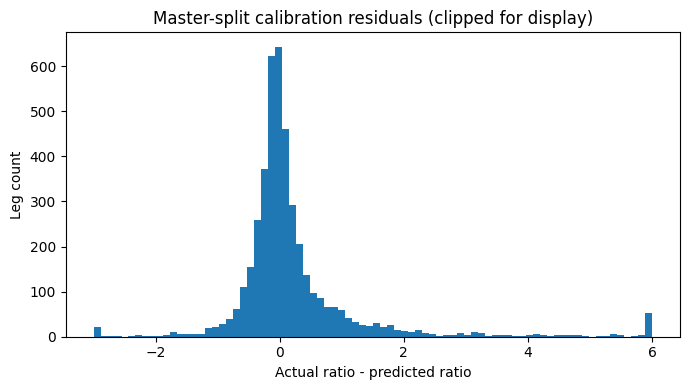

In [3]:
display(CAL["resid"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).to_frame("calibration_residual").round(3))

plt.figure(figsize=(7, 4))
plt.hist(CAL["resid"].clip(-3, 6), bins=80)
plt.title("Master-split calibration residuals (clipped for display)")
plt.xlabel("Actual ratio - predicted ratio")
plt.ylabel("Leg count")
plt.tight_layout()
plt.savefig(FIG / "calibration_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
def q_abs(scores, alpha):
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    if len(scores) == 0:
        raise ValueError("Cannot calibrate with zero finite scores.")
    s = np.sort(scores)
    k = min(int(np.ceil((len(s) + 1) * (1 - alpha))), len(s))
    return float(s[k - 1])

def q_signed(resid, alpha):
    resid = np.asarray(resid, dtype=float)
    resid = resid[np.isfinite(resid)]
    if len(resid) == 0:
        raise ValueError("Cannot calibrate with zero finite residuals.")
    s = np.sort(resid)
    n = len(s)
    k_hi = min(int(np.ceil((n + 1) * (1 - alpha / 2))), n)
    k_lo = max(int(np.floor((n + 1) * alpha / 2)), 1)
    return float(s[k_lo - 1]), float(s[k_hi - 1])

def interval_metrics(y, lo, hi, osrm, alpha):
    y, lo, hi, osrm = map(lambda x: np.asarray(x, dtype=float), (y, lo, hi, osrm))
    inside = (y >= lo) & (y <= hi)
    width = hi - lo
    score = width + (2 / alpha) * np.clip(lo - y, 0, None) + (2 / alpha) * np.clip(y - hi, 0, None)
    return {
        "coverage": float(inside.mean()),
        "mean_width_ratio": float(width.mean()),
        "median_width_ratio": float(np.median(width)),
        "mean_width_min": float((width * osrm).mean()),
        "interval_score": float(score.mean())
    }

def coverage_ci_by_trip(inside, trips, n_boot=2000, seed=42):
    # Resample trips, not individual legs, to respect within-trip dependence.
    frame = pd.DataFrame({"trip": np.asarray(trips), "inside": np.asarray(inside, dtype=float)})
    grouped = frame.groupby("trip")["inside"].agg(["sum", "count"])
    sums, counts = grouped["sum"].to_numpy(), grouped["count"].to_numpy()
    if len(grouped) < 2:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    estimates = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, len(grouped), len(grouped))
        estimates[b] = sums[idx].sum() / counts[idx].sum()
    return tuple(np.percentile(estimates, [2.5, 97.5]).round(3))

## Methods A and B — global split conformal

- **A:** symmetric margins from absolute calibration residuals.
- **B:** asymmetric lower/upper margins from signed calibration residuals.

In [5]:
rows_A, rows_B = [], []
y = TEST["y_ratio"].to_numpy()
pred = TEST["pred_ratio"].to_numpy()
osrm = TEST["osrm_time_min"].to_numpy()

for level, alpha in LEVELS.items():
    q = q_abs(CAL["resid"].abs().to_numpy(), alpha)
    lo = np.clip(pred - q, 0, None)
    hi = pred + q
    rows_A.append({
        "method": "A symmetric", "level": level, "target": 1 - alpha,
        **interval_metrics(y, lo, hi, osrm, alpha)
    })

    r_lo, r_hi = q_signed(CAL["resid"].to_numpy(), alpha)
    lo = np.clip(pred + r_lo, 0, None)
    hi = pred + r_hi
    rows_B.append({
        "method": "B asymmetric", "level": level, "target": 1 - alpha,
        **interval_metrics(y, lo, hi, osrm, alpha),
        "lo_offset": r_lo, "hi_offset": r_hi
    })

RES_A = pd.DataFrame(rows_A)
RES_B = pd.DataFrame(rows_B)
display(pd.concat([RES_A, RES_B], ignore_index=True).round(4))

,method,level,target,coverage,mean_width_ratio,median_width_ratio,mean_width_min,interval_score,lo_offset,hi_offset
0,A symmetric,50%,0.5,0.4743,0.4852,0.4852,41.8331,2.3832,NaN,NaN
1,A symmetric,80%,0.8,0.7899,1.3525,1.3525,116.6090,4.6506,NaN,NaN
2,A symmetric,90%,0.9,0.9001,2.4917,2.4981,214.9979,7.4297,NaN,NaN
3,B asymmetric,50%,0.5,0.4631,0.5019,0.5019,43.2741,2.3886,-0.2043,0.2977
4,B asymmetric,80%,0.8,0.7690,1.5049,1.5049,129.7487,4.5805,-0.4637,1.0413
5,B asymmetric,90%,0.9,0.8796,2.5866,2.5866,223.0067,7.1080,-0.6828,1.9038


## Calibration stability check

Split the calibration pile chronologically into early and late halves. This is a diagnostic only; the final test pile remains untouched.

In [6]:
cal_sorted = CAL.sort_values("od_start_time").reset_index(drop=True)
half = len(cal_sorted) // 2
EARLY, LATE = cal_sorted.iloc[:half], cal_sorted.iloc[half:]
if EARLY.empty or LATE.empty:
    raise ValueError("Not enough calibration rows for the chronological stability check.")

stability_rows = []
for level, alpha in LEVELS.items():
    q = q_abs(EARLY["resid"].abs().to_numpy(), alpha)
    cov_a = (LATE["resid"].abs().to_numpy() <= q).mean()
    r_lo, r_hi = q_signed(EARLY["resid"].to_numpy(), alpha)
    cov_b = ((LATE["resid"].to_numpy() >= r_lo) &
             (LATE["resid"].to_numpy() <= r_hi)).mean()
    stability_rows.append({
        "level": level, "target": 1 - alpha,
        "A_symmetric_coverage": cov_a,
        "B_asymmetric_coverage": cov_b
    })
STABILITY = pd.DataFrame(stability_rows)
display(STABILITY.round(4))
STABILITY.to_csv(CAL_OUT / "chronological_calibration_check.csv", index=False)

,level,target,A_symmetric_coverage,B_asymmetric_coverage
0,50%,0.5,0.4728,0.4742
1,80%,0.8,0.7950,0.7908
2,90%,0.9,0.8894,0.8870


## Slices and grouped conformal

Distance tercile boundaries are calculated from calibration data only. Method C groups by route type × distance bucket. Method D adds a low/normal lane-history flag. Small groups fall back to global calibration offsets.

In [7]:
distance_edges = CAL["osrm_distance_km"].quantile([1/3, 2/3]).to_numpy()

def add_slices(frame):
    d = frame.copy()
    d["dist_bucket"] = pd.cut(
        d["osrm_distance_km"],
        [-np.inf, distance_edges[0], distance_edges[1], np.inf],
        labels=["short", "medium", "long"],
        include_lowest=True
    ).astype("object").fillna("unknown")
    d["hist_bucket"] = pd.cut(
        d["lane_history_count"],
        [-np.inf, 0, 2, 9, np.inf],
        labels=["0 (unseen)", "1-2", "3-9", "10+"],
        include_lowest=True
    ).astype("object").fillna("unknown")
    d["weekend"] = np.where(d["od_start_time"].dt.dayofweek >= 5, "weekend", "weekday")
    d["day"] = d["od_start_time"].dt.strftime("%Y-%m-%d")
    return d

CAL_S = add_slices(CAL)
TEST_S = add_slices(TEST)

def set_group(frame, method):
    d = frame.copy()
    d["grp"] = d["route_type"].astype(str) + "|" + d["dist_bucket"].astype(str)
    if method == "D":
        d["lowhist"] = np.where(d["lane_history_count"] < 3, "low", "ok")
        d["grp"] = d["grp"] + "|" + d["lowhist"]
    return d

def grouped_bounds(cal_frame, alpha, min_n):
    global_offsets = q_signed(cal_frame["resid"].to_numpy(), alpha)
    offsets, counts = {}, {}
    for group, group_df in cal_frame.groupby("grp", dropna=False):
        counts[str(group)] = int(len(group_df))
        offsets[str(group)] = (
            q_signed(group_df["resid"].to_numpy(), alpha)
            if len(group_df) >= min_n else global_offsets
        )
    return offsets, global_offsets, counts

def apply_grouped(frame, offsets, global_offsets):
    chosen = [offsets.get(str(g), global_offsets) for g in frame["grp"]]
    lo_off = np.array([x[0] for x in chosen], dtype=float)
    hi_off = np.array([x[1] for x in chosen], dtype=float)
    lo = np.clip(frame["pred_ratio"].to_numpy() + lo_off, 0, None)
    hi = frame["pred_ratio"].to_numpy() + hi_off
    return lo, hi

def slice_table(frame, lo, hi, columns):
    d = frame.copy()
    d["inside"] = (d["y_ratio"].to_numpy() >= lo) & (d["y_ratio"].to_numpy() <= hi)
    d["width_ratio"] = hi - lo
    parts = []
    for col in columns:
        part = d.groupby(col, observed=True, dropna=False).agg(
            n=("inside", "size"),
            coverage=("inside", "mean"),
            mean_width_ratio=("width_ratio", "mean")
        ).reset_index().rename(columns={col: "group"})
        part.insert(0, "slice", col)
        parts.append(part)
    return pd.concat(parts, ignore_index=True).round(4)

In [8]:
MIN_N_C = 200
MIN_N_D = 100
rows_C, rows_D = [], []
group_counts = {}

CAL_C, TEST_C = set_group(CAL_S, "C"), set_group(TEST_S, "C")
CAL_D, TEST_D = set_group(CAL_S, "D"), set_group(TEST_S, "D")

for level, alpha in LEVELS.items():
    offsets_c, global_c, counts_c = grouped_bounds(CAL_C, alpha, MIN_N_C)
    lo_c, hi_c = apply_grouped(TEST_C, offsets_c, global_c)
    rows_C.append({
        "method": "C grouped (route x distance)", "level": level, "target": 1 - alpha,
        **interval_metrics(TEST_C["y_ratio"], lo_c, hi_c, TEST_C["osrm_time_min"], alpha)
    })

    offsets_d, global_d, counts_d = grouped_bounds(CAL_D, alpha, MIN_N_D)
    lo_d, hi_d = apply_grouped(TEST_D, offsets_d, global_d)
    rows_D.append({
        "method": "D grouped (route x distance x history)", "level": level, "target": 1 - alpha,
        **interval_metrics(TEST_D["y_ratio"], lo_d, hi_d, TEST_D["osrm_time_min"], alpha)
    })
    if level == "90%":
        group_counts = {
            "C": {"min_group_size": MIN_N_C, "counts": counts_c},
            "D": {"min_group_size": MIN_N_D, "counts": counts_d}
        }

RES_C, RES_D = pd.DataFrame(rows_C), pd.DataFrame(rows_D)
ALL_METHODS = pd.concat([RES_A, RES_B, RES_C, RES_D], ignore_index=True)
display(ALL_METHODS.round(4))
ALL_METHODS.to_csv(OUT / "interval_comparison_all_methods.csv", index=False)

# 90% slice diagnostics for selected grouped methods
a90 = LEVELS["90%"]
off_c, glob_c, _ = grouped_bounds(CAL_C, a90, MIN_N_C)
lo_c90, hi_c90 = apply_grouped(TEST_C, off_c, glob_c)
SLICE_C = slice_table(TEST_S, lo_c90, hi_c90,
                      ["route_type", "dist_bucket", "hist_bucket", "weekend", "day"])
SLICE_C.to_csv(OUT / "method_c_90pct_slice_diagnostics.csv", index=False)
display(SLICE_C)

,method,level,target,coverage,mean_width_ratio,median_width_ratio,mean_width_min,interval_score,lo_offset,hi_offset
0,A symmetric,50%,0.5,0.4743,0.4852,0.4852,41.8331,2.3832,NaN,NaN
1,A symmetric,80%,0.8,0.7899,1.3525,1.3525,116.6090,4.6506,NaN,NaN
2,A symmetric,90%,0.9,0.9001,2.4917,2.4981,214.9979,7.4297,NaN,NaN
3,B asymmetric,50%,0.5,0.4631,0.5019,0.5019,43.2741,2.3886,-0.2043,0.2977
4,B asymmetric,80%,0.8,0.7690,1.5049,1.5049,129.7487,4.5805,-0.4637,1.0413
5,B asymmetric,90%,0.9,0.8796,2.5866,2.5866,223.0067,7.1080,-0.6828,1.9038
6,C grouped (route x distance),50%,0.5,0.4615,0.5619,0.4838,33.8259,2.3594,NaN,NaN
7,C grouped (route x distance),80%,0.8,0.7763,1.5760,1.5220,98.7403,4.4358,NaN,NaN
8,C grouped (route x distance),90%,0.9,0.8885,2.8092,2.3529,164.8442,6.7695,NaN,NaN
9,D grouped (route x distance x history),50%,0.5,0.4465,0.5446,0.5019,33.8697,2.3595,NaN,NaN


,slice,group,n,coverage,mean_width_ratio
0,route_type,Carting,2187,0.8930,3.8852
1,route_type,FTL,2207,0.8840,1.7429
2,dist_bucket,long,1459,0.8965,1.6262
3,dist_bucket,medium,1470,0.8639,2.2789
4,dist_bucket,short,1465,0.9051,4.5194
5,hist_bucket,0 (unseen),240,0.7667,2.4950
6,hist_bucket,1-2,265,0.8453,2.3414
7,hist_bucket,10+,2943,0.9049,2.9664
8,hist_bucket,3-9,946,0.8805,2.5309
9,weekend,weekday,3536,0.8903,2.7919


## Coverage uncertainty and reliability

The bootstrap resamples trips rather than individual legs because legs from the same trip may be correlated.

,level,target,coverage,trip_bootstrap_95_lo,trip_bootstrap_95_hi
0,50%,0.5,0.4631,0.448,0.478
1,80%,0.8,0.7690,0.756,0.782
2,90%,0.9,0.8796,0.870,0.889


,level,target,coverage,trip_bootstrap_95_lo,trip_bootstrap_95_hi
0,50%,0.5,0.4615,0.446,0.477
1,80%,0.8,0.7763,0.764,0.789
2,90%,0.9,0.8885,0.879,0.898


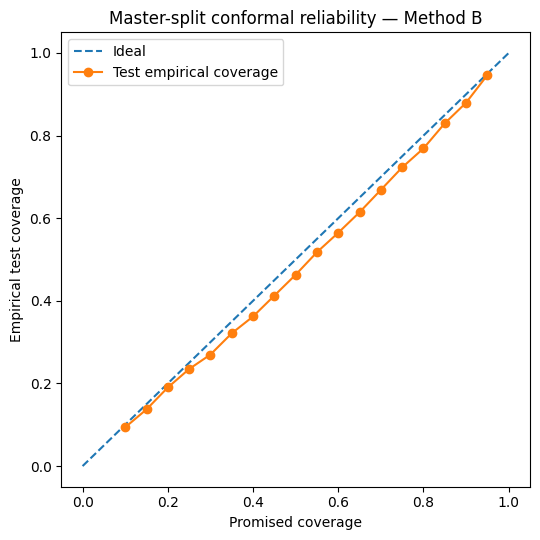

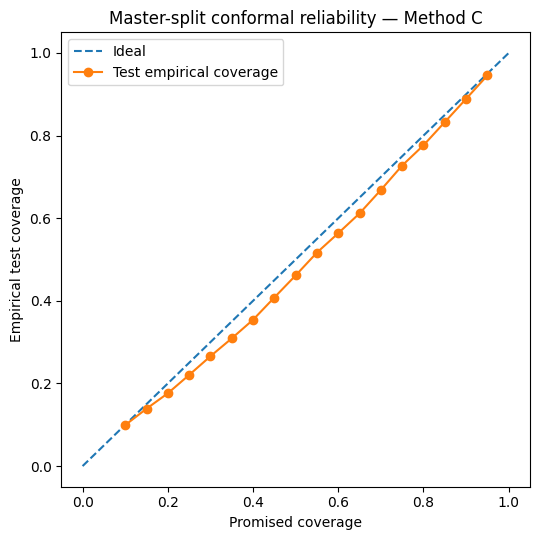

Method B and Method C bootstrap and reliability outputs saved.


In [9]:

# Trip-bootstrap coverage confidence intervals for Methods B and C
# Resample trips (not individual legs) to respect within-trip dependence.

# -----------------------------
# Method B: Asymmetric conformal
# -----------------------------
ci_rows_b = []

for level, alpha in LEVELS.items():
    r_lo, r_hi = q_signed(CAL["resid"].to_numpy(), alpha)

    lo = np.clip(TEST["pred_ratio"].to_numpy() + r_lo, 0, None)
    hi = TEST["pred_ratio"].to_numpy() + r_hi

    inside = (
        (TEST["y_ratio"].to_numpy() >= lo) &
        (TEST["y_ratio"].to_numpy() <= hi)
    )

    ci_lo, ci_hi = coverage_ci_by_trip(
        inside,
        TEST["trip_uuid"].to_numpy(),
        seed=42
    )

    ci_rows_b.append({
        "level": level,
        "target": 1 - alpha,
        "coverage": inside.mean(),
        "trip_bootstrap_95_lo": ci_lo,
        "trip_bootstrap_95_hi": ci_hi
    })

COVERAGE_CI_B = pd.DataFrame(ci_rows_b)
display(COVERAGE_CI_B.round(4))

COVERAGE_CI_B.to_csv(
    OUT / "method_b_trip_bootstrap_coverage_ci.csv",
    index=False
)


# -----------------------------
# Method C: Grouped conformal
# -----------------------------
ci_rows_c = []

for level, alpha in LEVELS.items():
    offsets_c, global_c, _ = grouped_bounds(
        CAL_C, alpha, MIN_N_C
    )

    lo, hi = apply_grouped(
        TEST_C, offsets_c, global_c
    )

    inside = (
        (TEST_C["y_ratio"].to_numpy() >= lo) &
        (TEST_C["y_ratio"].to_numpy() <= hi)
    )

    ci_lo, ci_hi = coverage_ci_by_trip(
        inside,
        TEST_C["trip_uuid"].to_numpy(),
        seed=43
    )

    ci_rows_c.append({
        "level": level,
        "target": 1 - alpha,
        "coverage": inside.mean(),
        "trip_bootstrap_95_lo": ci_lo,
        "trip_bootstrap_95_hi": ci_hi
    })

COVERAGE_CI_C = pd.DataFrame(ci_rows_c)
display(COVERAGE_CI_C.round(4))

COVERAGE_CI_C.to_csv(
    OUT / "method_c_trip_bootstrap_coverage_ci.csv",
    index=False
)


# -----------------------------
# Reliability plot: Method B
# -----------------------------
promised = np.arange(0.10, 0.96, 0.05)

empirical_b = []

for target in promised:
    r_lo, r_hi = q_signed(
        CAL["resid"].to_numpy(), 1 - target
    )

    lo = np.clip(TEST["pred_ratio"].to_numpy() + r_lo, 0, None)
    hi = TEST["pred_ratio"].to_numpy() + r_hi

    empirical_b.append(
        (
            (TEST["y_ratio"].to_numpy() >= lo) &
            (TEST["y_ratio"].to_numpy() <= hi)
        ).mean()
    )

plt.figure(figsize=(5.5, 5.5))
plt.plot([0, 1], [0, 1], "--", label="Ideal")
plt.plot(promised, empirical_b, marker="o",
         label="Test empirical coverage")
plt.xlabel("Promised coverage")
plt.ylabel("Empirical test coverage")
plt.title("Master-split conformal reliability — Method B")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIG / "conformal_reliability_method_b.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# -----------------------------
# Reliability plot: Method C
# -----------------------------
empirical_c = []

for target in promised:
    offsets_c, global_c, _ = grouped_bounds(
        CAL_C, 1 - target, MIN_N_C
    )

    lo, hi = apply_grouped(
        TEST_C, offsets_c, global_c
    )

    empirical_c.append(
        (
            (TEST_C["y_ratio"].to_numpy() >= lo) &
            (TEST_C["y_ratio"].to_numpy() <= hi)
        ).mean()
    )

plt.figure(figsize=(5.5, 5.5))
plt.plot([0, 1], [0, 1], "--", label="Ideal")
plt.plot(promised, empirical_c, marker="o",
         label="Test empirical coverage")
plt.xlabel("Promised coverage")
plt.ylabel("Empirical test coverage")
plt.title("Master-split conformal reliability — Method C")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIG / "conformal_reliability_method_c.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Method B and Method C bootstrap and reliability outputs saved.")


## Method E — rolling recalibration eligibility

Rolling calibration requires a trustworthy `od_end_time` for every calibration and test leg. The B02 master-split prediction file currently contains no `od_end_time` column. This notebook therefore **does not join the old calibration/test split files**, because those may belong to the previous split and could silently misalign the new master split.

If an authoritative master-split end-time source is added later, Method E can be implemented as a separately validated extension. Until then, Methods A–D are the supported comparisons for this master split.

In [10]:
ROLLING_STATUS = {
    "method": "E rolling recalibration",
    "status": "not_run",
    "reason": (
        "The B02 master-split prediction file has no od_end_time. "
        "Old split files are not joined because their trip/leg membership may not match this master split."
    )
}
with open(OUT / "method_e_rolling_status.json", "w", encoding="utf-8") as f:
    json.dump(ROLLING_STATUS, f, indent=2)
print(ROLLING_STATUS["status"] + ": " + ROLLING_STATUS["reason"])

not_run: The B02 master-split prediction file has no od_end_time. Old split files are not joined because their trip/leg membership may not match this master split.


## Final output — Method C (static grouped conformal)

Method C is retained as the primary candidate from the previous Day 3 work, but its results are recalculated on the new master split. Review the new comparison table before treating it as the final operational choice.

In [11]:
# Refit final Method C offsets on the full calibration pile; apply only to test.
final_offsets, final_global, final_counts = grouped_bounds(CAL_C, a90, MIN_N_C)
final_lo90, final_hi90 = apply_grouped(TEST_C, final_offsets, final_global)

test_final = TEST.copy()
test_final["dist_bucket"] = TEST_C["dist_bucket"].to_numpy()
test_final["grp"] = TEST_C["grp"].to_numpy()

# Also provide all three requested interval levels.
levels_out = {}
for level, alpha in LEVELS.items():
    offsets, global_offsets, counts = grouped_bounds(CAL_C, alpha, MIN_N_C)
    lo, hi = apply_grouped(TEST_C, offsets, global_offsets)
    tag = level.replace("%", "")
    test_final[f"lower_{tag}"] = lo
    test_final[f"upper_{tag}"] = hi
    test_final[f"excess_lower_{tag}_min"] = (lo - 1) * test_final["osrm_time_min"]
    test_final[f"excess_upper_{tag}_min"] = (hi - 1) * test_final["osrm_time_min"]
    levels_out[level] = {
        "alpha": alpha,
        "global_offsets": [float(global_offsets[0]), float(global_offsets[1])],
        "group_offsets": {str(g): [float(v[0]), float(v[1])] for g, v in offsets.items()},
        "group_counts": counts
    }

test_final["pred_excess_min"] = (
    test_final["pred_ratio"] - 1
) * test_final["osrm_time_min"]

# Optimizer-facing columns first, retain route/time context after them.
optimizer_cols = [
    "trip_uuid", "source_center", "destination_center", "route_type",
    "od_start_time", "osrm_time_min", "osrm_distance_km",
    "lane_history_count", "pile", "pred_ratio", "pred_excess_min",
    "lower_50", "upper_50", "lower_80", "upper_80", "lower_90", "upper_90",
    "excess_lower_50_min", "excess_upper_50_min",
    "excess_lower_80_min", "excess_upper_80_min",
    "excess_lower_90_min", "excess_upper_90_min", "dist_bucket", "grp"
]
test_final = test_final[optimizer_cols].copy()

params_final = {
    "experiment": "day3_master_split_v2",
    "input_prediction_file": str(INPUT_PRED.relative_to(ROOT)),
    "frozen_model": "B02 residual XGBoost predictions; no model retraining in B03",
    "method": "C: grouped (route_type x calibration-distance-tercile) split conformal on signed residuals",
    "min_group_size": MIN_N_C,
    "distance_edges_km": [float(x) for x in distance_edges],
    "calibration_legs": int(len(CAL)),
    "calibration_trips": int(CAL["trip_uuid"].nunique()),
    "test_legs": int(len(TEST)),
    "test_trips": int(TEST["trip_uuid"].nunique()),
    "levels": levels_out,
    "method_e": ROLLING_STATUS
}

# Intentional rerun behavior: overwrite only these files inside master_split_v2/.
test_final.to_csv(FINAL / "test_intervals_method_c_master_split_v2.csv", index=False)
with open(FINAL / "conformal_params_method_c_master_split_v2.json", "w", encoding="utf-8") as f:
    json.dump(params_final, f, indent=2)
ALL_METHODS.to_csv(FINAL / "interval_comparison_master_split_v2.csv", index=False)
print("Saved final Method C predictions:", FINAL / "test_intervals_method_c_master_split_v2.csv")
print("Rows:", len(test_final), "| columns:", len(test_final.columns))
display(test_final.head())

Saved final Method C predictions: C:\Local\Documents-Local\ML Project\supplyshield--1\experiments\day3\master_split_v2\final\test_intervals_method_c_master_split_v2.csv
Rows: 4394 | columns: 25


,trip_uuid,source_center,destination_center,route_type,od_start_time,osrm_time_min,osrm_distance_km,lane_history_count,pile,pred_ratio,...,lower_90,upper_90,excess_lower_50_min,excess_upper_50_min,excess_lower_80_min,excess_upper_80_min,excess_lower_90_min,excess_upper_90_min,dist_bucket,grp
0,trip-153825367809847590,IND781018AAB,IND110037AAM,FTL,2018-09-29 20:41:18.098697,1323.0,1808.0123,12,test,2.471345,...,2.022573,3.591255,1766.474792,2182.643346,1545.092453,2827.749859,1352.864140,3428.230913,long,FTL|long
1,trip-153825373348100973,IND400072AAB,IND000000AFT,Carting,2018-09-29 20:42:13.481254,18.0,21.5787,52,test,2.312178,...,1.290999,6.401399,18.545096,34.847404,12.487597,58.783313,5.237974,97.225177,short,Carting|short
2,trip-153825378089249497,IND842001AAA,IND847212AAA,FTL,2018-09-29 20:43:00.892752,72.0,95.5397,17,test,2.099271,...,1.650499,3.219182,69.345383,91.994012,57.297364,127.101849,46.835959,159.781090,long,FTL|long
3,trip-153825378089249497,IND847212AAA,IND847226AAA,FTL,2018-09-30 01:49:27.443064,30.0,38.5395,16,test,1.819032,...,1.212118,2.975820,18.539912,30.702937,12.349751,43.380373,6.363554,59.274599,medium,FTL|medium
4,trip-153825378089249497,IND847226AAA,IND842001AAA,FTL,2018-09-30 04:09:54.834217,83.0,117.9869,16,test,8.773688,...,8.324916,9.893599,633.916414,660.025250,620.027726,700.496785,607.968051,738.168688,long,FTL|long


In [12]:
# Final integrity checks and output manifest
final_path = FINAL / "test_intervals_method_c_master_split_v2.csv"
params_path = FINAL / "conformal_params_method_c_master_split_v2.json"
comparison_path = FINAL / "interval_comparison_master_split_v2.csv"

required_outputs = [
    final_path,
    params_path,
    comparison_path,
    OUT / "interval_comparison_all_methods.csv",
    OUT / "method_c_90pct_slice_diagnostics.csv",
    OUT / "method_b_trip_bootstrap_coverage_ci.csv",
    OUT / "method_c_trip_bootstrap_coverage_ci.csv",
    OUT / "method_e_rolling_status.json",
    CAL_OUT / "chronological_calibration_check.csv",
    FIG / "calibration_residuals.png",
    FIG / "conformal_reliability_method_b.png",
    FIG / "conformal_reliability_method_c.png"
]

missing_outputs = [str(p.relative_to(ROOT)) for p in required_outputs if not p.is_file()]
if missing_outputs:
    raise FileNotFoundError(f"Cannot mark Day 3 complete; outputs missing: {missing_outputs}")

saved = pd.read_csv(final_path)
assert len(saved) == len(TEST), "Final output row count differs from test pile."
assert saved["trip_uuid"].notna().all(), "Final output has missing trip_uuid."
assert saved["pred_ratio"].notna().all(), "Final output has missing predictions."
interval_cols = ["lower_50", "upper_50", "lower_80", "upper_80", "lower_90", "upper_90"]
assert saved[interval_cols].notna().all().all(), "Final intervals contain missing values."
assert (saved["lower_50"] <= saved["upper_50"]).all()
assert (saved["lower_80"] <= saved["upper_80"]).all()
assert (saved["lower_90"] <= saved["upper_90"]).all()
assert saved["trip_uuid"].nunique() == TEST["trip_uuid"].nunique()

manifest = {
    "status": "complete",
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "input": str(INPUT_PRED.relative_to(ROOT)),
    "experiment_dir": str(EXP.relative_to(ROOT)),
    "outputs": sorted(str(p.relative_to(ROOT)) for p in EXP.rglob("*")
                      if p.is_file() and p.name not in {"_RUNNING.json", "_SUCCESS.json"}),
    "test_rows": int(len(saved)),
    "test_trips": int(saved["trip_uuid"].nunique()),
    "rerun_policy": "At notebook start, clear only experiments/day3/master_split_v2; older Day 3 folders are untouched.",
    "team_consumption_rule": "Use these outputs only when _SUCCESS.json exists and status is complete."
}
with open(EXP / "run_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

# Publish success marker LAST. If execution stops before this line, there is
# no success marker and teammates must treat the folder as incomplete.
if RUNNING_MARKER.exists():
    RUNNING_MARKER.unlink()
with open(SUCCESS_MARKER, "w", encoding="utf-8") as f:
    json.dump({
        "status": "complete",
        "completed_at_utc": manifest["completed_at_utc"],
        "manifest": str((EXP / "run_manifest.json").relative_to(ROOT))
    }, f, indent=2)

print("ALL FINAL CHECKS PASSED")
print("DAY 3 STATUS: COMPLETE")
print("Team handoff marker:", SUCCESS_MARKER.relative_to(ROOT))
print("Experiment folder:", EXP.relative_to(ROOT))
print("Files written:", len(manifest["outputs"]) + 2)
for path in manifest["outputs"]:
    print(" -", path)

ALL FINAL CHECKS PASSED
DAY 3 STATUS: COMPLETE
Team handoff marker: experiments\day3\master_split_v2\_SUCCESS.json
Experiment folder: experiments\day3\master_split_v2
Files written: 14
 - experiments\day3\master_split_v2\calibration\chronological_calibration_check.csv
 - experiments\day3\master_split_v2\evaluation\interval_comparison_all_methods.csv
 - experiments\day3\master_split_v2\evaluation\method_b_trip_bootstrap_coverage_ci.csv
 - experiments\day3\master_split_v2\evaluation\method_c_90pct_slice_diagnostics.csv
 - experiments\day3\master_split_v2\evaluation\method_c_trip_bootstrap_coverage_ci.csv
 - experiments\day3\master_split_v2\evaluation\method_e_rolling_status.json
 - experiments\day3\master_split_v2\figures\calibration_residuals.png
 - experiments\day3\master_split_v2\figures\conformal_reliability_method_b.png
 - experiments\day3\master_split_v2\figures\conformal_reliability_method_c.png
 - experiments\day3\master_split_v2\final\conformal_params_method_c_master_split_v2.js

## Interpretation notes

- Compare Methods A–D using the newly generated `interval_comparison_all_methods.csv`; do not reuse the old Day 3 metric values.
- Method C's saved test intervals are the primary candidate artifact for downstream work. Its performance must be judged from the new master-split results.
- Method E is explicitly marked `not_run` until a verified end-time source aligned to the master split is available.
- The notebook does not modify B02 predictions, old Day 3 outputs, B04/B05 notebooks, or Day 5 artifacts.

**Team handoff rule:** Teammates must check for `experiments/day3/master_split_v2/_SUCCESS.json` before consuming any Day 3 outputs. No success marker means the run is incomplete or failed.